# 7 · United States vs European Union: working capital, debt, distress and the cash locked in receivables
This notebook produces every figure in the US-EU case study. It covers **11,387 US companies and 6,441 companies in the 27 EU member states** (2000-2020), compared on working capital, profitability, debt, cash and financial distress, followed by a ranking of EU countries and an estimate of the cash EU companies would release if they collected as fast as US companies. The UK is shown separately as a reference, since it is no longer an EU member.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
EU27 = {"AUT", "BEL", "BGR", "HRV", "CYP", "CZE", "DNK", "EST", "FIN", "FRA", "DEU", "GRC", "HUN", "IRL", "ITA", "LVA", "LTU", "LUX", "MLT", "NLD",
        "POL", "PRT", "ROU", "SVK", "SVN", "ESP", "SWE"}
p["bloc"] = np.select([p["loc"].eq("USA"), p["loc"].isin(EU27), p["loc"].eq("GBR")], ["USA", "EU-27", "UK"], default="")
q = p[p.bloc != ""].copy()
first = q.groupby("gvkey")["fyear"].transform("min")
q["established"] = (q.at_usd >= 100) & (q.fyear - first >= 5); has_debt = q.interest_cover.notna()
print(q.groupby("bloc").agg(firms=("gvkey", "nunique"), firm_years=("gvkey", "size"), countries=("loc", "nunique")))

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


       firms  firm_years  countries
bloc                               
EU-27   6441       76664         27
UK      2658       26430          1
USA    11387       97555          1


## 1. The headline comparison

In [2]:
g = q.groupby("bloc")
t = pd.DataFrame({"median assets, USD m": g.at_usd.median(), "receivable days": g.dso.median(), "inventory days": g.dio.median(),
                  "payable days": g.dpo.median(), "cash conversion cycle": g.ccc.median(), "operating ROA %": 100 * g.roa.median(),
                  "book leverage %": 100 * g.leverage.median(), "cash / assets %": 100 * g.cash.median(),
                  "zombie % (established, indebted)": 100 * q[has_debt & q.established].groupby("bloc").zombie.mean(),
                  "Altman Z'' distress % (established)": 100 * (q[q.established].z_score < 1.1).groupby(q[q.established].bloc).mean()}).T[["USA", "EU-27", "UK"]]
t.round(1).to_csv(DATA / "usa_eu_headline.csv"); t.round(1)

bloc,USA,EU-27,UK
"median assets, USD m",245.95,110.27,86.23
receivable days,51.89,78.57,69.46
inventory days,32.01,56.07,31.76
payable days,42.55,65.34,60.3
cash conversion cycle,50.01,78.36,50.71
operating ROA %,4.13,4.47,4.95
book leverage %,21.83,19.52,13.89
cash / assets %,10.83,8.28,9.49
"zombie % (established, indebted)",11.49,9.37,5.83
Altman Z'' distress % (established),21.29,25.57,26.45


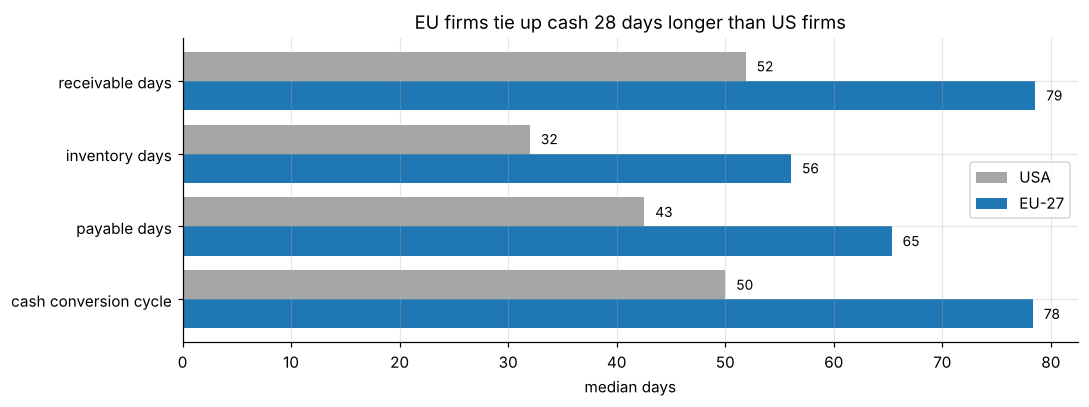

In [3]:
w_ = t.loc[["receivable days", "inventory days", "payable days", "cash conversion cycle"], ["USA", "EU-27"]]
fig, ax = plt.subplots(figsize=(10, 3.8)); yy = np.arange(len(w_))
ax.barh(yy - 0.2, w_["USA"], 0.4, color="0.65", label="USA"); ax.barh(yy + 0.2, w_["EU-27"], 0.4, color="C0", label="EU-27")
for i, (a, b) in enumerate(zip(w_["USA"], w_["EU-27"])): ax.text(a + 1, i - 0.2, f"{a:.0f}", va="center", fontsize=9); ax.text(b + 1, i + 0.2, f"{b:.0f}", va="center", fontsize=9)
ax.set_yticks(yy, w_.index); ax.invert_yaxis(); ax.legend(); ax.set_xlabel("median days")
ax.set_title(f"EU firms tie up cash {w_.loc['cash conversion cycle', 'EU-27'] - w_.loc['cash conversion cycle', 'USA']:.0f} days longer than US firms")
plt.tight_layout(); plt.savefig(IMG / "usa_eu_working_capital.png", bbox_inches="tight"); plt.show()

## 2. Europe is not one market

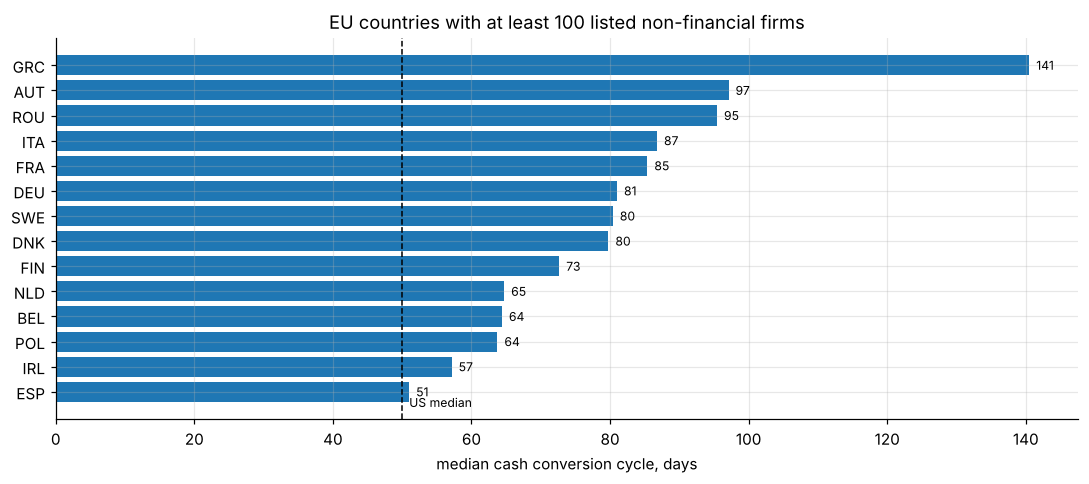

,receivable days,inventory days,payable days,cycle,ROA %,leverage %,firms,firm_years
loc,,,,,,,,
ESP,96.1,67.0,125.7,51.0,4.8,29.3,187,2462
IRL,61.2,44.2,58.1,57.1,6.3,22.3,139,1506
POL,73.9,46.5,66.1,63.7,4.7,13.8,765,8886
BEL,78.3,58.8,74.1,64.4,5.2,23.5,152,1986
NLD,69.0,42.7,59.5,64.7,6.4,22.5,257,2847
FIN,62.5,58.1,44.6,72.7,5.7,23.7,195,2647
DNK,69.4,60.7,55.3,79.8,5.5,19.9,199,2423
SWE,74.1,56.8,54.5,80.4,2.0,12.7,923,10281
DEU,62.6,63.6,47.8,81.0,4.5,15.8,1051,12137


In [4]:
eu = q[q.bloc == "EU-27"]
ec = aggregate.summary(eu.assign(roa_pct=100 * eu.roa, lev=100 * eu.leverage), "loc", ["dso", "dio", "dpo", "ccc", "roa_pct", "lev"], min_firms=100).sort_values("ccc")
ec.columns = ["receivable days", "inventory days", "payable days", "cycle", "ROA %", "leverage %", "firms", "firm_years"]
ref = t.loc[["receivable days", "inventory days", "payable days", "cash conversion cycle"], "USA"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(ec.index, ec["cycle"], color="C0"); ax.axvline(ref["cash conversion cycle"], color="k", ls="--", lw=1); ax.text(ref["cash conversion cycle"] + 1, -0.6, "US median", fontsize=8)
for i, v in enumerate(ec["cycle"]): ax.text(v + 1, i, f"{v:.0f}", va="center", fontsize=8)
ax.set_xlabel("median cash conversion cycle, days"); ax.set_title("EU countries with at least 100 listed non-financial firms")
plt.tight_layout(); plt.savefig(IMG / "eu_country_cycles.png", bbox_inches="tight"); plt.show()
ec.round(1).to_csv(DATA / "eu_countries_working_capital.csv"); ec.round(1)

## 3. How much cash would faster collection release?
For each EU company in fiscal 2019, the receivables above what it would hold at the US median collection period are **(DSO − US median DSO) / 365 × sales**, counted only where positive. Summed across companies, this is the cash released if every EU company collected as fast as the median US company. The first estimate ignores sector mix; the second uses the US median *for the same industry*. **Autos & components are excluded**: carmakers' receivables include the car loans and leases of their captive finance arms, which are lending, not trade credit (they alone would add about USD 200bn). Even so, a few large companies account for a big share of the total, so the figures are an order of magnitude, not a forecast.

In [5]:
y = 2019
us19 = q[(q.bloc == "USA") & (q.fyear == y)]; us_dso = us19.dso.median(); us_dso_ind = us19.groupby("industry").dso.median()
rel = {}
for b in ["EU-27", "UK"]:
    s = q[(q.bloc == b) & (q.fyear == y) & (q.industry_group != "2510")].dropna(subset=["dso", "sale_usd"])
    flat = ((s.dso - us_dso).clip(lower=0) / 365 * s.sale_usd).sum() / 1000
    ind = ((s.dso - s.industry.map(us_dso_ind)).clip(lower=0) / 365 * s.sale_usd).sum() / 1000
    firm = ((s.dso - s.industry.map(us_dso_ind)).clip(lower=0) / 365 * s.sale_usd)
    rel[b] = {"companies (2019)": len(s), "sales, USD bn": s.sale_usd.sum() / 1000, "release vs US median DSO, USD bn": flat,
              "release vs US median of same industry, USD bn": ind, "share from the 10 largest contributors %": 100 * firm.nlargest(10).sum() / firm.sum()}
rel = pd.DataFrame(rel).T
by_c = q[(q.bloc == "EU-27") & (q.fyear == y) & (q.industry_group != "2510")].dropna(subset=["dso", "sale_usd"])
by_c = ((by_c.dso - by_c.industry.map(us_dso_ind)).clip(lower=0) / 365 * by_c.sale_usd).groupby(by_c["loc"]).sum().sort_values(ascending=False) / 1000
display(rel.round(1))
print("Largest contributions (same-industry benchmark), USD bn:", by_c.head(6).round(0).to_dict())

,companies (2019),"sales, USD bn","release vs US median DSO, USD bn","release vs US median of same industry, USD bn",share from the 10 largest contributors %
EU-27,3512.0,6341.8,421.7,453.1,22.5
UK,942.0,1782.4,78.8,99.4,57.4


Largest contributions (same-industry benchmark), USD bn: {'FRA': 147.0, 'DEU': 114.0, 'ITA': 42.0, 'ESP': 34.0, 'SWE': 29.0, 'NLD': 23.0}


## 4. Does faster collection pay, and how have debt and zombie firms evolved?

,ROA change (pts) per 100 more receivable days,t,firm-years
USA,-0.43,-3.15,84992.0
EU-27,-0.38,-4.79,67948.0
UK,-0.57,-3.64,23446.0


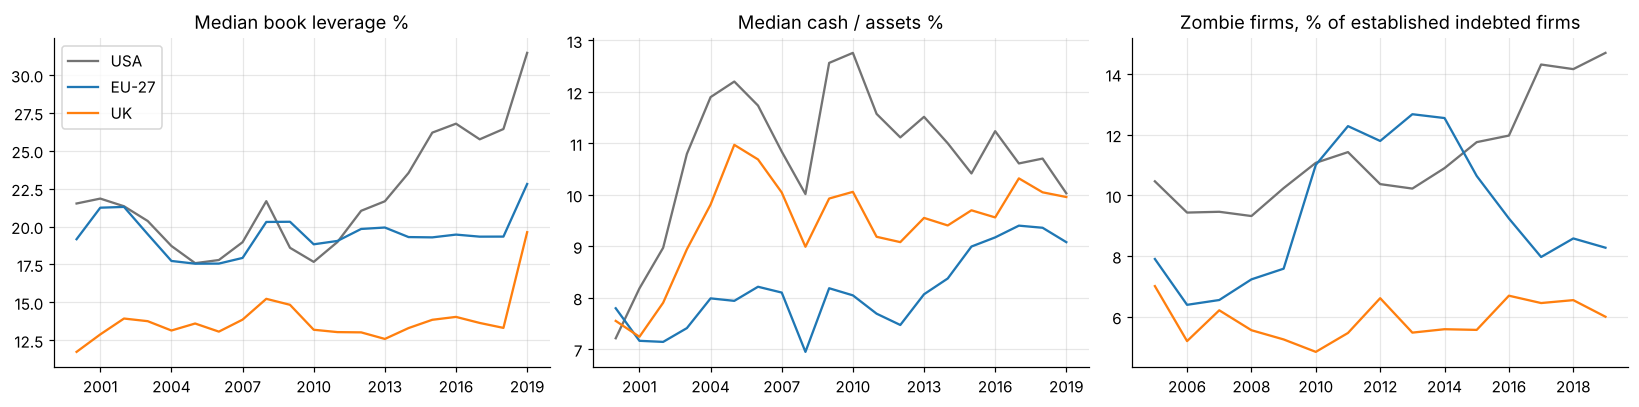

bloc,EU-27,UK,USA
leverage 2000,19.16,11.73,21.52
leverage 2019,22.81,19.63,31.45
zombie 2008,7.23,5.56,9.32
zombie 2019,8.28,6.0,14.7


In [6]:
q["dso_100"] = q.dso / 100; q["roa_pct"] = 100 * q.roa
fe = {}
for b in ["USA", "EU-27", "UK"]:
    r_ = regress.fe(q[q.bloc == b], "roa_pct", ["dso_100", "size", "sales_growth", "leverage"])
    fe[b] = {"ROA change (pts) per 100 more receivable days": r_.loc["dso_100", "coef"], "t": r_.loc["dso_100", "t"], "firm-years": r_.attrs["nobs"]}
display(pd.DataFrame(fe).T.round(2))
ty = q[q.fyear <= 2019].groupby(["fyear", "bloc"])[["leverage", "cash"]].median().unstack() * 100
zy = q[has_debt & q.established & (q.fyear.between(2005, 2019))].groupby(["fyear", "bloc"]).zombie.mean().unstack() * 100
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (d, ttl) in zip(ax, [(ty["leverage"], "Median book leverage %"), (ty["cash"], "Median cash / assets %"), (zy, "Zombie firms, % of established indebted firms")]):
    for b, c in [("USA", "0.45"), ("EU-27", "C0"), ("UK", "C1")]: a.plot(d.index, d[b], color=c, label=b)
    a.set_title(ttl); int_years(a)
ax[0].legend(); plt.tight_layout(); plt.savefig(IMG / "usa_eu_trends.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"leverage 2000": ty["leverage"].loc[2000], "leverage 2019": ty["leverage"].loc[2019], "zombie 2008": zy.loc[2008], "zombie 2019": zy.loc[2019]}).T.round(1)

## Findings
* **EU companies tie up cash 28 days longer than US companies.** The median cash conversion cycle is 78 vs 50 days. EU firms collect from customers in 79 days (US 52) and hold 56 days of inventory (US 32), partly offset by paying suppliers in 65 days (US 43). UK firms sit close to the US on the cycle (51 days) despite slower collection, because they also pay slowly.
* **Profitability is similar** (operating ROA 4.5% EU, 4.1% US), but EU firms are half the size (median assets USD 110m vs 246m) and hold less cash (8% vs 11% of assets).
* **Europe is not one market.** Median cycles run from 51 days in Spain and 57 in Ireland to 81 in Germany, 85 in France, 87 in Italy and 141 in Greece. Southern Europe both collects and pays slowly: Italian and Spanish firms wait 120 and 96 days for customers and take 119 and 126 days to pay suppliers.
* **The cash locked in slow collection is large.** Benchmarking each EU company in 2019 against the US median for its own industry, receivables above that level total about **USD 450 billion** on USD 6.3 trillion of sales (USD 420 billion against the overall US median). France (147bn) and Germany (114bn) account for most of it. Autos & components are excluded, because carmakers' receivables include customer car loans; they would add about USD 200 billion more. The ten largest contributors account for 23% of the total.
* **Faster collection pays on both sides of the Atlantic.** Within the same firm, 100 more receivable days cut operating ROA by 0.4 points in the US (t = -3.2) and the EU (t = -4.8), and by 0.6 in the UK.
* **US companies re-levered and the zombie share rose.** US median leverage went from 22% (2000) to 31% (2019), EU from 19% to 23%. Part of the 2019 jump on both sides is lease capitalisation (ASC 842 and IFRS 16). Among established indebted companies, the US zombie share rose from 9% in 2008 to 15% in 2019, while the EU's peaked near 13% during the euro crisis (2011-2014) and fell back to 8%.